# Fashion-MNIST – Exploratory Data Analysis

## Objective

The objective of this notebook is to explore the structure,
quality and statistical characteristics of the Fashion-MNIST
dataset before developing machine learning and deep learning
models.

The analysis focuses on:

- Dataset structure and dimensionality
- Data quality and duplicate observations
- Class distribution and balance
- Pixel intensity statistics
- Visual characteristics of clothing categories
- Implications for subsequent model development

Exploratory analyses are performed on the original training
dataset. The official test dataset is reserved for final
model evaluation.

## 1. Setup and Data Loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

# Project configuration
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Locate project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Output directory
FIGURES_DIR = PROJECT_ROOT / "results" / "figures" / "eda"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Visualization settings
PROJECT_PALETTE = [
    "#DFE9EF",
    "#BDCEDB",
    "#8FA7BD",
    "#5E7891",
    "#32485F",
    "#1E3247",
    "#0F1B2A",
]

PRIMARY_COLOR = "#5E7891"
SECONDARY_COLOR = "#32485F"
ACCENT_COLOR = "#8FA7BD"

sns.set_theme(
    style="whitegrid",
    palette=PROJECT_PALETTE,
)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
    }
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Figure output directory: {FIGURES_DIR}")
print(f"PyTorch version: {torch.__version__}")

Project root: c:\Users\SUB\OneDrive - Horváth & Partner GmbH\Asztal\Github\DLProject_FashionMNIST
Figure output directory: c:\Users\SUB\OneDrive - Horváth & Partner GmbH\Asztal\Github\DLProject_FashionMNIST\results\figures\eda
PyTorch version: 2.7.1+cpu


In [2]:
from src.preprocessing.dataset import load_dataset

train_dataset, test_dataset = load_dataset()

print(f"Original training samples: {len(train_dataset):,}")
print(f"Official test samples: {len(test_dataset):,}")

Original training samples: 60,000
Official test samples: 10,000


In [3]:
# Extract raw training images and labels
images = train_dataset.data.numpy()
labels = train_dataset.targets.numpy()

# Extract class names
class_names = train_dataset.classes

print(f"Image array shape: {images.shape}")
print(f"Image data type: {images.dtype}")
print(f"Label array shape: {labels.shape}")
print(f"Number of classes: {len(class_names)}")

print("\nClass mapping:")

for class_id, class_name in enumerate(class_names):
    print(f"{class_id}: {class_name}")

Image array shape: (60000, 28, 28)
Image data type: uint8
Label array shape: (60000,)
Number of classes: 10

Class mapping:
0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot


## 2. Dataset Overview

This section summarizes the structural characteristics of the
Fashion-MNIST dataset, including the number of observations,
image dimensionality, data types and target variable.

In [4]:
dataset_summary = pd.DataFrame(
    {
        "Characteristic": [
            "Original training samples",
            "Official test samples",
            "Total samples",
            "Image height",
            "Image width",
            "Color channels",
            "Pixels per image",
            "Image data type",
            "Label data type",
            "Number of classes",
            "Minimum pixel value",
            "Maximum pixel value",
        ],
        "Value": [
            len(train_dataset),
            len(test_dataset),
            len(train_dataset) + len(test_dataset),
            images.shape[1],
            images.shape[2],
            1,
            images.shape[1] * images.shape[2],
            str(images.dtype),
            str(labels.dtype),
            len(class_names),
            images.min(),
            images.max(),
        ],
    }
)

display(dataset_summary)

,Characteristic,Value
0,Original training samples,60000
1,Official test samples,10000
2,Total samples,70000
3,Image height,28
4,Image width,28
5,Color channels,1
6,Pixels per image,784
7,Image data type,uint8
8,Label data type,int64
9,Number of classes,10


## 3. Data Quality Assessment

The purpose of this section is to identify potential data
quality issues that may affect model training and evaluation.

The following aspects are investigated:

- Missing values
- Invalid pixel values
- Invalid class labels
- Consistency of images and labels
- Exact duplicate images
- Duplicate images with conflicting labels

### 3.1. Structural and Value Consistency Checks

In [5]:
quality_checks = pd.DataFrame(
    {
        "Check": [
            "Missing pixel values",
            "Missing labels",
            "Invalid pixel values",
            "Invalid class labels",
            "Image-label count mismatch",
            "Unexpected image dimensions",
            "Completely black images",
            "Completely white images",
        ],
        "Count": [
            np.isnan(images).sum(),
            np.isnan(labels).sum(),
            ((images < 0) | (images > 255)).sum(),
            (~np.isin(labels, np.arange(len(class_names)))).sum(),
            abs(len(images) - len(labels)),
            int(images.shape[1:] != (28, 28)),
            np.all(images == 0, axis=(1, 2)).sum(),
            np.all(images == 255, axis=(1, 2)).sum(),
        ],
    }
)

quality_checks["Status"] = np.where(
    quality_checks["Count"] == 0,
    "OK",
    "Review required",
)

display(quality_checks)

,Check,Count,Status
0,Missing pixel values,0,OK
1,Missing labels,0,OK
2,Invalid pixel values,0,OK
3,Invalid class labels,0,OK
4,Image-label count mismatch,0,OK
5,Unexpected image dimensions,0,OK
6,Completely black images,0,OK
7,Completely white images,0,OK


### 3.2. Exact Duplicate Images

Exact duplicate images are identified by comparing their raw
pixel representations.

Duplicate observations may reduce the effective diversity of
the dataset and potentially introduce data leakage if identical
images are assigned to different dataset splits.

In [6]:
import hashlib

image_hashes = [hashlib.sha256(image.tobytes()).hexdigest() for image in images]

image_metadata = pd.DataFrame(
    {
        "image_index": np.arange(len(images)),
        "image_hash": image_hashes,
        "label": labels,
    }
)

hash_counts = image_metadata["image_hash"].value_counts()

duplicate_groups = hash_counts[hash_counts > 1]

duplicate_summary = pd.DataFrame(
    {
        "Characteristic": [
            "Total images",
            "Unique images",
            "Duplicate image groups",
            "Images belonging to duplicate groups",
            "Redundant duplicate images",
        ],
        "Count": [
            len(images),
            len(hash_counts),
            len(duplicate_groups),
            duplicate_groups.sum(),
            len(images) - len(hash_counts),
        ],
    }
)

display(duplicate_summary)

,Characteristic,Count
0,Total images,60000
1,Unique images,60000
2,Duplicate image groups,0
3,Images belonging to duplicate groups,0
4,Redundant duplicate images,0


### 3.3. Duplicate Images with Conflicting Labels

Identical images associated with different class labels may
indicate inconsistent annotation and introduce ambiguity
into the classification task.

In [7]:
label_counts_per_image = image_metadata.groupby("image_hash")["label"].nunique()

conflicting_hashes = label_counts_per_image[label_counts_per_image > 1].index

conflicting_images = image_metadata[image_metadata["image_hash"].isin(conflicting_hashes)]

conflict_summary = pd.DataFrame(
    {
        "Characteristic": [
            "Duplicate groups with conflicting labels",
            "Images affected by conflicting labels",
        ],
        "Count": [
            len(conflicting_hashes),
            len(conflicting_images),
        ],
    }
)

display(conflict_summary)

,Characteristic,Count
0,Duplicate groups with conflicting labels,0
1,Images affected by conflicting labels,0


### 3.4. Key Findings

All structural and value consistency checks were passed.

- No missing or invalid pixel values were identified.
- All class labels are within the expected range.
- All images have the expected dimensions.
- No completely black or white images were detected.
- All 60,000 training images are unique.
- No exact duplicates with conflicting labels were found.

Based on these checks, no data cleaning or duplicate
removal is required.

However, these results do not rule out near-duplicate
images or incorrectly annotated individual samples.

## 4. Class Distribution

This section investigates the distribution of clothing
categories in the original training dataset.

The analysis evaluates class frequencies, relative
frequencies and potential class imbalance, which may
influence model training and evaluation.

In [8]:
class_distribution = pd.DataFrame(
    {
        "Class ID": np.arange(len(class_names)),
        "Class": class_names,
        "Frequency": np.bincount(
            labels,
            minlength=len(class_names),
        ),
    }
)

class_distribution["Relative Frequency (%)"] = class_distribution["Frequency"] / len(labels) * 100

display(class_distribution)

min_frequency = class_distribution["Frequency"].min()
max_frequency = class_distribution["Frequency"].max()

imbalance_ratio = max_frequency / min_frequency

print(f"Minimum class frequency: {min_frequency:,}")
print(f"Maximum class frequency: {max_frequency:,}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

,Class ID,Class,Frequency,Relative Frequency (%)
0,0,T-shirt/top,6000,10.0
1,1,Trouser,6000,10.0
2,2,Pullover,6000,10.0
3,3,Dress,6000,10.0
4,4,Coat,6000,10.0
5,5,Sandal,6000,10.0
6,6,Shirt,6000,10.0
7,7,Sneaker,6000,10.0
8,8,Bag,6000,10.0
9,9,Ankle boot,6000,10.0


Minimum class frequency: 6,000
Maximum class frequency: 6,000
Imbalance ratio: 1.00


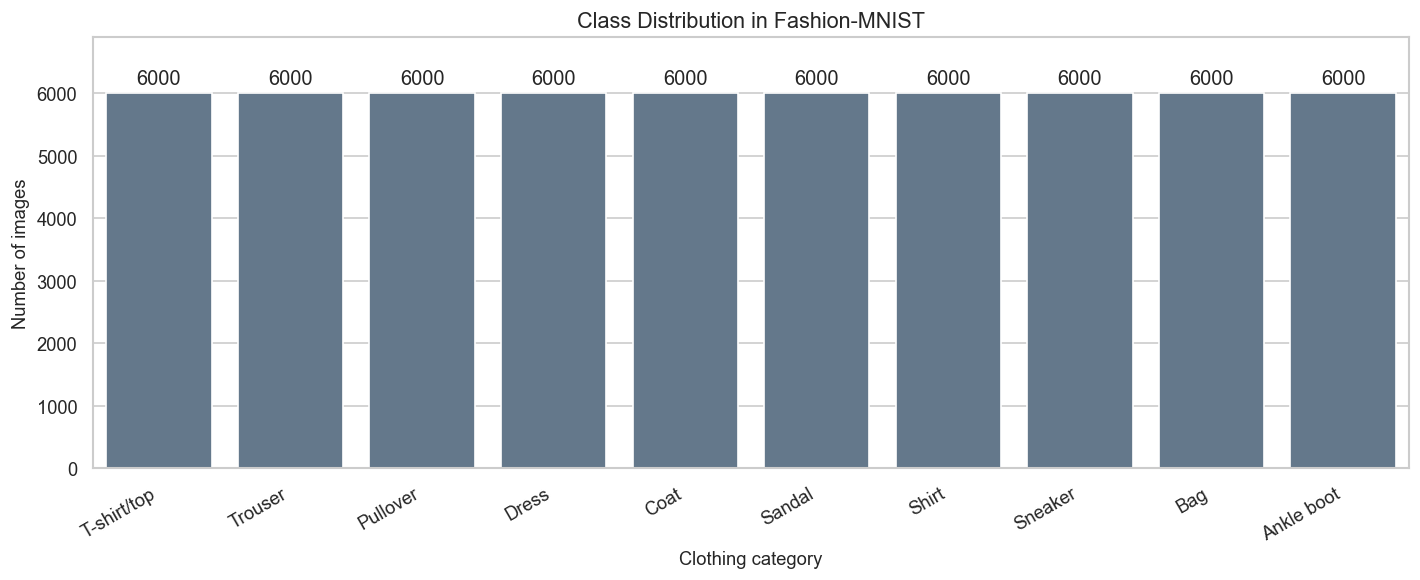

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Frequency",
    color=PRIMARY_COLOR,
    ax=ax,
)

ax.set_title("Class Distribution in Fashion-MNIST")
ax.set_xlabel("Clothing category")
ax.set_ylabel("Number of images")
ax.set_ylim(0, max_frequency * 1.15)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "class_distribution.png",
    bbox_inches="tight",
)

plt.show()

### Key Findings

The original training dataset is perfectly balanced,
with 6,000 images per class and an imbalance ratio of 1.00.

Therefore, class balancing techniques such as oversampling,
undersampling or frequency-based class weighting are not
required for the baseline models.

Stratified sampling is recommended when creating the
training and validation subsets to preserve the original
class distribution.

## 5. Pixel Intensity Analysis

Pixel intensity statistics provide insights into the
brightness, variability and sparsity of the image data.

The analysis examines both the overall pixel intensity
distribution and differences between clothing categories.

### 5.1. Overall Pixel Statistics

In [10]:
pixel_summary = pd.DataFrame(
    {
        "Statistic": [
            "Number of pixels",
            "Minimum",
            "Maximum",
            "Mean",
            "Standard deviation",
            "Median",
            "25th percentile",
            "75th percentile",
            "Zero-valued pixels (%)",
            "Maximum-intensity pixels (%)",
        ],
        "Value": [
            images.size,
            images.min(),
            images.max(),
            images.mean(),
            images.std(),
            np.median(images),
            np.percentile(images, 25),
            np.percentile(images, 75),
            (images == 0).mean() * 100,
            (images == 255).mean() * 100,
        ],
    }
)

display(pixel_summary.style.format({"Value": "{:,.4f}"}))

,Statistic,Value
0,Number of pixels,"47,040,000.0000"
1,Minimum,0.0000
2,Maximum,255.0000
3,Mean,72.9404
4,Standard deviation,90.0212
5,Median,0.0000
6,25th percentile,0.0000
7,75th percentile,163.0000
8,Zero-valued pixels (%),50.2051
9,Maximum-intensity pixels (%),0.8059


### 5.2. Pixel Intensity Distribution

The histogram illustrates the frequency of grayscale
pixel intensities across the original training dataset.

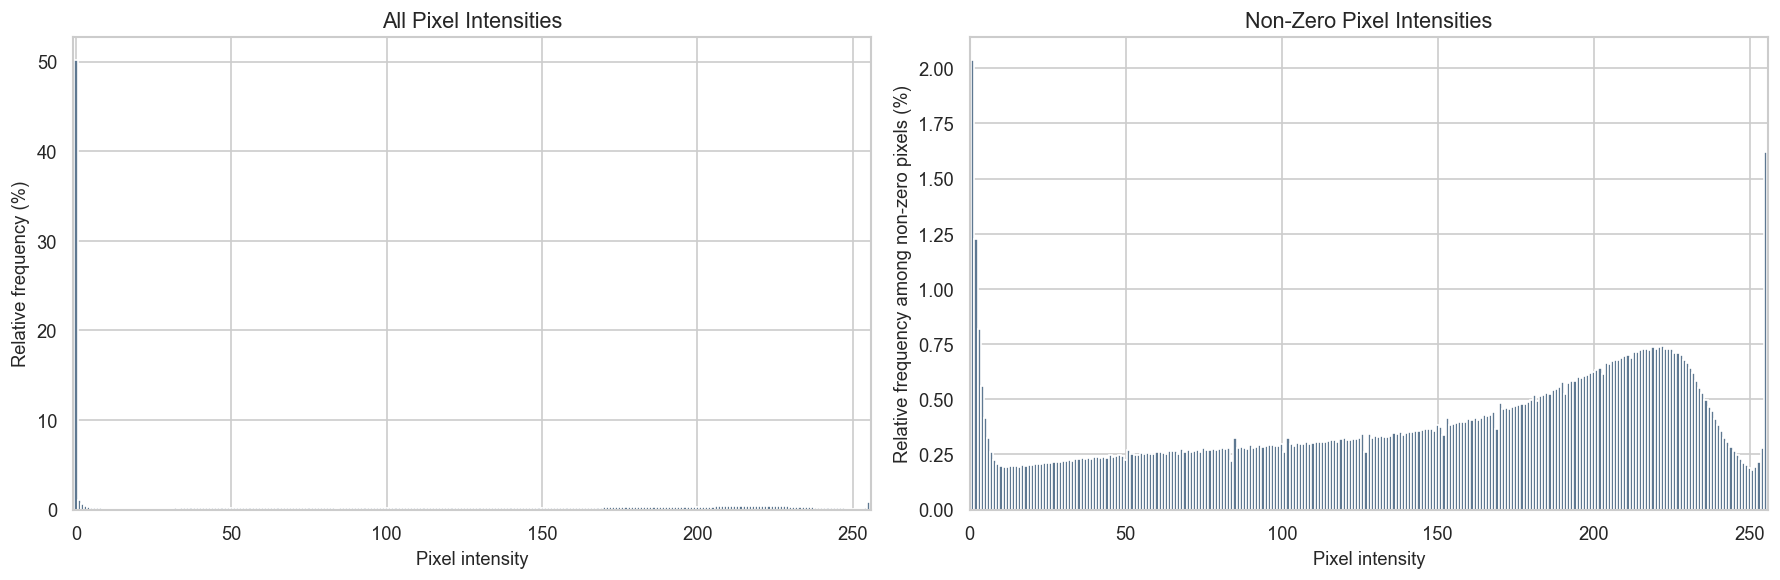

In [11]:
pixel_counts = np.bincount(
    images.ravel(),
    minlength=256,
)

pixel_relative_frequency = pixel_counts / images.size * 100

nonzero_relative_frequency = pixel_counts[1:] / pixel_counts[1:].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Overall pixel distribution
axes[0].bar(
    np.arange(256),
    pixel_relative_frequency,
    width=1,
    color=PRIMARY_COLOR,
)

axes[0].set_title("All Pixel Intensities")
axes[0].set_xlabel("Pixel intensity")
axes[0].set_ylabel("Relative frequency (%)")
axes[0].set_xlim(-1, 256)

# Conditional distribution of non-zero pixels
axes[1].bar(
    np.arange(1, 256),
    nonzero_relative_frequency,
    width=1,
    color=PRIMARY_COLOR,
)

axes[1].set_title("Non-Zero Pixel Intensities")
axes[1].set_xlabel("Pixel intensity")
axes[1].set_ylabel("Relative frequency among non-zero pixels (%)")
axes[1].set_xlim(0, 256)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "pixel_intensity_distribution.png",
    bbox_inches="tight",
)

plt.show()

### 5.3. Class-Level Pixel Statistics

Pixel intensity statistics are calculated separately
for each clothing category to identify differences
in brightness, variability and background coverage.

In [12]:
class_pixel_stats = []

for class_id, class_name in enumerate(class_names):
    class_images = images[labels == class_id]

    class_pixel_stats.append(
        {
            "Class": class_name,
            "Mean intensity": class_images.mean(),
            "Standard deviation": class_images.std(),
            "Zero-valued pixels (%)": ((class_images == 0).mean() * 100),
            "Maximum-intensity pixels (%)": ((class_images == 255).mean() * 100),
        }
    )

class_pixel_stats = pd.DataFrame(class_pixel_stats)

display(class_pixel_stats.round(2))

,Class,Mean intensity,Standard deviation,Zero-valued pixels (%),Maximum-intensity pixels (%)
0,T-shirt/top,83.03,89.44,40.59,0.59
1,Trouser,56.84,87.60,65.13,1.23
2,Pullover,96.06,91.46,35.13,1.28
3,Dress,66.02,90.33,57.21,0.85
4,Coat,98.26,95.96,39.83,0.97
5,Sandal,34.87,67.09,67.89,0.43
6,Shirt,84.61,86.52,37.09,0.66
7,Sneaker,42.76,75.17,66.21,0.43
8,Bag,90.16,93.14,41.44,0.76
9,Ankle boot,76.81,94.49,51.55,0.86


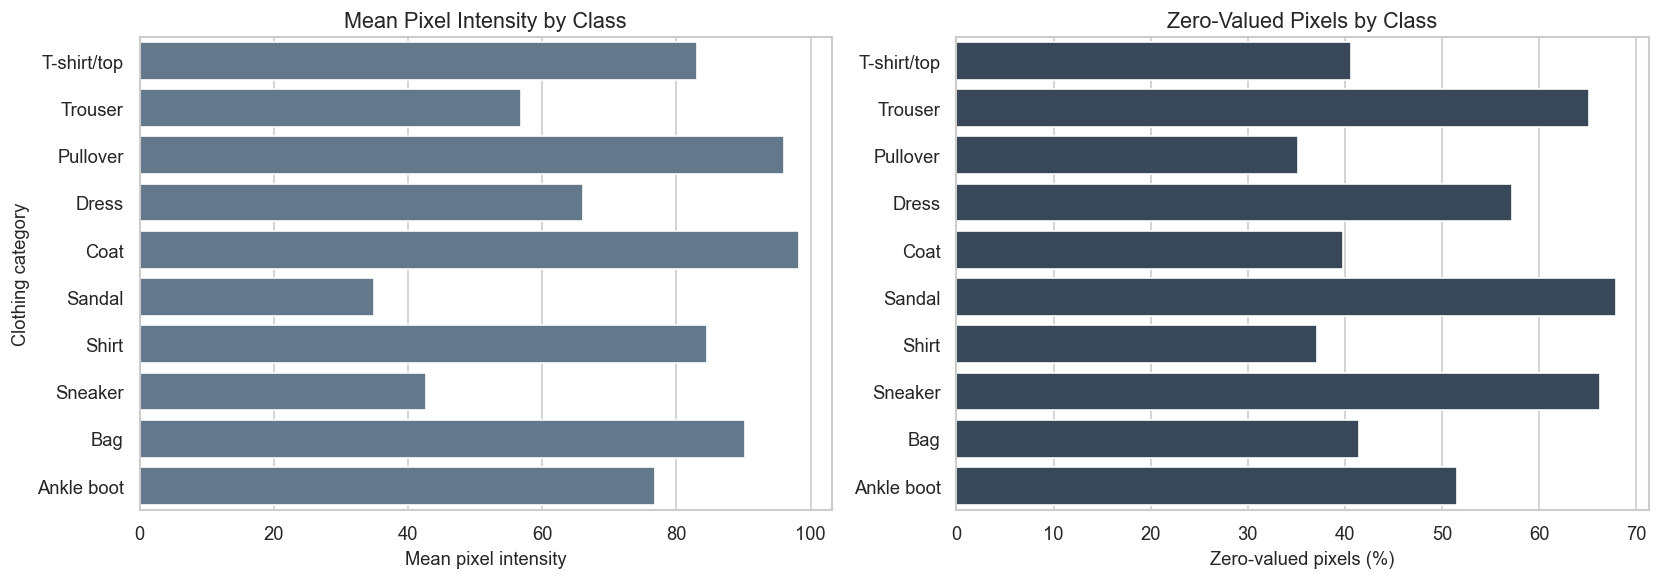

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=class_pixel_stats,
    y="Class",
    x="Mean intensity",
    color=PRIMARY_COLOR,
    ax=axes[0],
)

axes[0].set_title("Mean Pixel Intensity by Class")
axes[0].set_xlabel("Mean pixel intensity")
axes[0].set_ylabel("Clothing category")

sns.barplot(
    data=class_pixel_stats,
    y="Class",
    x="Zero-valued pixels (%)",
    color=SECONDARY_COLOR,
    ax=axes[1],
)

axes[1].set_title("Zero-Valued Pixels by Class")
axes[1].set_xlabel("Zero-valued pixels (%)")
axes[1].set_ylabel("")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "class_pixel_statistics.png",
    bbox_inches="tight",
)

plt.show()

### 5.4. Key Findings

The dataset contains approximately 47 million pixels,
with intensity values ranging from 0 to 255.

- The mean pixel intensity is 72.94, with a standard
  deviation of 90.02.
- Approximately 50.21% of all pixels have zero intensity,
  reflecting the predominantly black image backgrounds.
- Pixel intensity statistics differ substantially across
  clothing categories.
- Coats and pullovers have relatively high mean intensities,
  whereas sandals and sneakers contain a higher proportion
  of zero-valued pixels.
- Similar global pixel statistics across certain categories
  suggest that spatial features may be important for
  accurate classification.

These observations support investigating models that
can effectively capture spatial image characteristics.

Any data-dependent normalization parameters must be
estimated exclusively from the final training subset.

## 6. Image Exploration

This section explores the visual characteristics of
the clothing categories using representative sample
images and class-level mean images.

The objective is to identify within-class variability,
between-class similarities and spatial patterns that
may influence classification performance.

### 6.1. Random Sample Images by Class

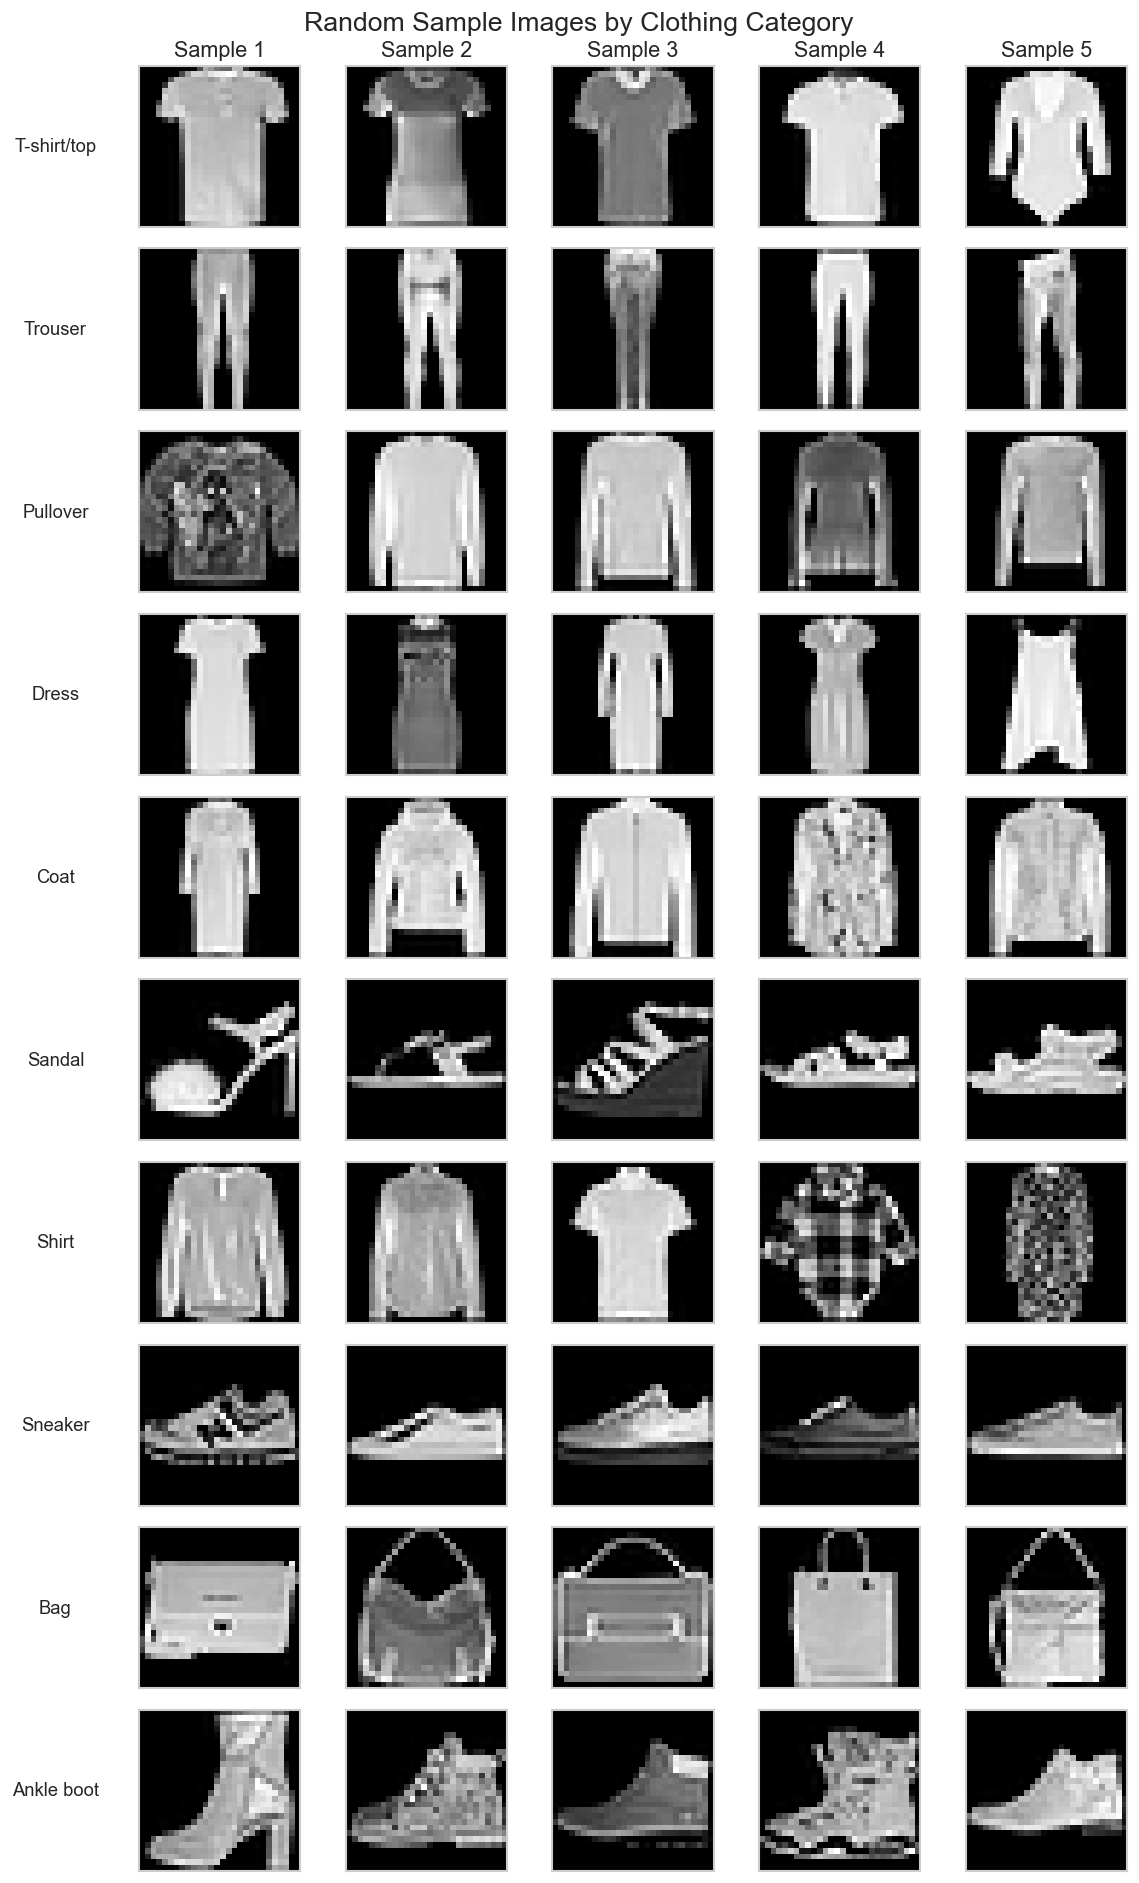

In [14]:
N_SAMPLES_PER_CLASS = 5

rng = np.random.default_rng(RANDOM_SEED)

fig, axes = plt.subplots(
    len(class_names),
    N_SAMPLES_PER_CLASS,
    figsize=(10, 16),
)

for class_id, class_name in enumerate(class_names):
    class_indices = np.where(labels == class_id)[0]

    sample_indices = rng.choice(
        class_indices,
        size=N_SAMPLES_PER_CLASS,
        replace=False,
    )

    for col, image_index in enumerate(sample_indices):
        ax = axes[class_id, col]

        ax.imshow(
            images[image_index],
            cmap="gray",
            vmin=0,
            vmax=255,
        )

        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)

        if col == 0:
            ax.set_ylabel(
                class_name,
                rotation=0,
                labelpad=50,
                va="center",
            )

        if class_id == 0:
            ax.set_title(f"Sample {col + 1}")

fig.suptitle(
    "Random Sample Images by Clothing Category",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "sample_images.png",
    bbox_inches="tight",
)

plt.show()

### 6.2. Class-Level Mean Images

Mean images are calculated by averaging pixel
intensities at each spatial position across all
images belonging to the same clothing category.

This visualization highlights characteristic shapes,
spatial patterns and similarities between classes.

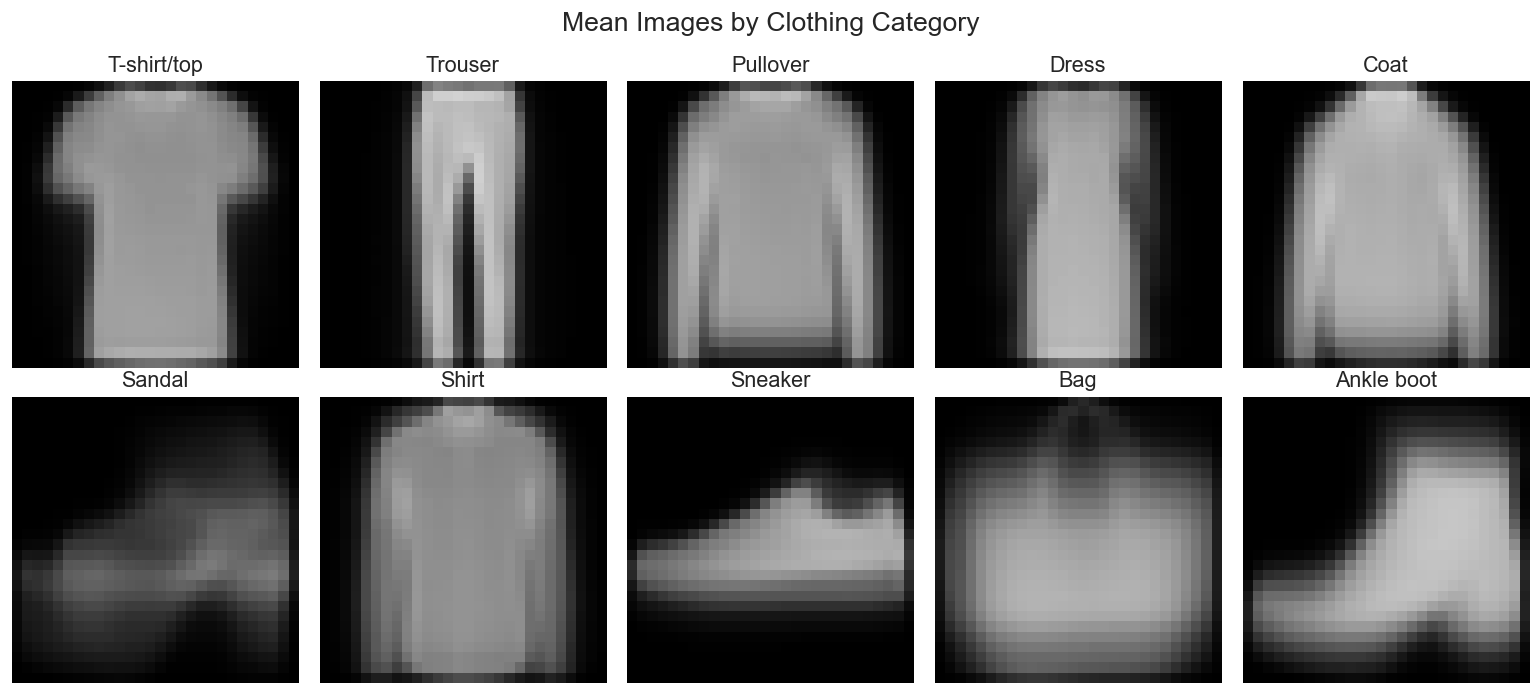

In [15]:
class_mean_images = np.stack(
    [images[labels == class_id].mean(axis=0) for class_id in range(len(class_names))]
)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(13, 6),
)

for class_id, ax in enumerate(axes.ravel()):
    ax.imshow(
        class_mean_images[class_id],
        cmap="gray",
        vmin=0,
        vmax=255,
    )

    ax.set_title(class_names[class_id])
    ax.axis("off")

fig.suptitle(
    "Mean Images by Clothing Category",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "class_mean_images.png",
    bbox_inches="tight",
)

plt.show()

### 6.3. Inter-Class Cosine Similarity

Cosine similarity is used to quantify the visual
similarity between class-level mean images.

Each mean image is represented as a 784-dimensional
pixel vector. Pairwise cosine similarities are
calculated to identify clothing categories with
similar average spatial patterns.

The resulting similarity matrix may provide insights
into potential classification difficulties and serve
as a reference for the subsequent analysis of model
confusion matrices.

In [16]:
from sklearn.metrics.pairwise import cosine_similarity

# Flatten class-level mean images
mean_image_vectors = class_mean_images.reshape(len(class_names), -1)

# Calculate pairwise cosine similarities
similarity_matrix = cosine_similarity(mean_image_vectors)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=class_names,
    columns=class_names,
)

display(similarity_df.round(3))

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,1.000,0.837,0.899,0.924,0.906,0.609,0.949,0.518,0.795,0.668
Trouser,0.837,1.000,0.753,0.925,0.792,0.471,0.793,0.440,0.623,0.529
Pullover,0.899,0.753,1.000,0.828,0.984,0.739,0.983,0.627,0.893,0.756
Dress,0.924,0.925,0.828,1.000,0.868,0.568,0.886,0.517,0.741,0.626
Coat,0.906,0.792,0.984,0.868,1.000,0.732,0.987,0.632,0.894,0.750
Sandal,0.609,0.471,0.739,0.568,0.732,1.000,0.722,0.913,0.887,0.927
Shirt,0.949,0.793,0.983,0.886,0.987,0.722,1.000,0.615,0.894,0.748
Sneaker,0.518,0.440,0.627,0.517,0.632,0.913,0.615,1.000,0.787,0.795
Bag,0.795,0.623,0.893,0.741,0.894,0.887,0.894,0.787,1.000,0.863
Ankle boot,0.668,0.529,0.756,0.626,0.750,0.927,0.748,0.795,0.863,1.000


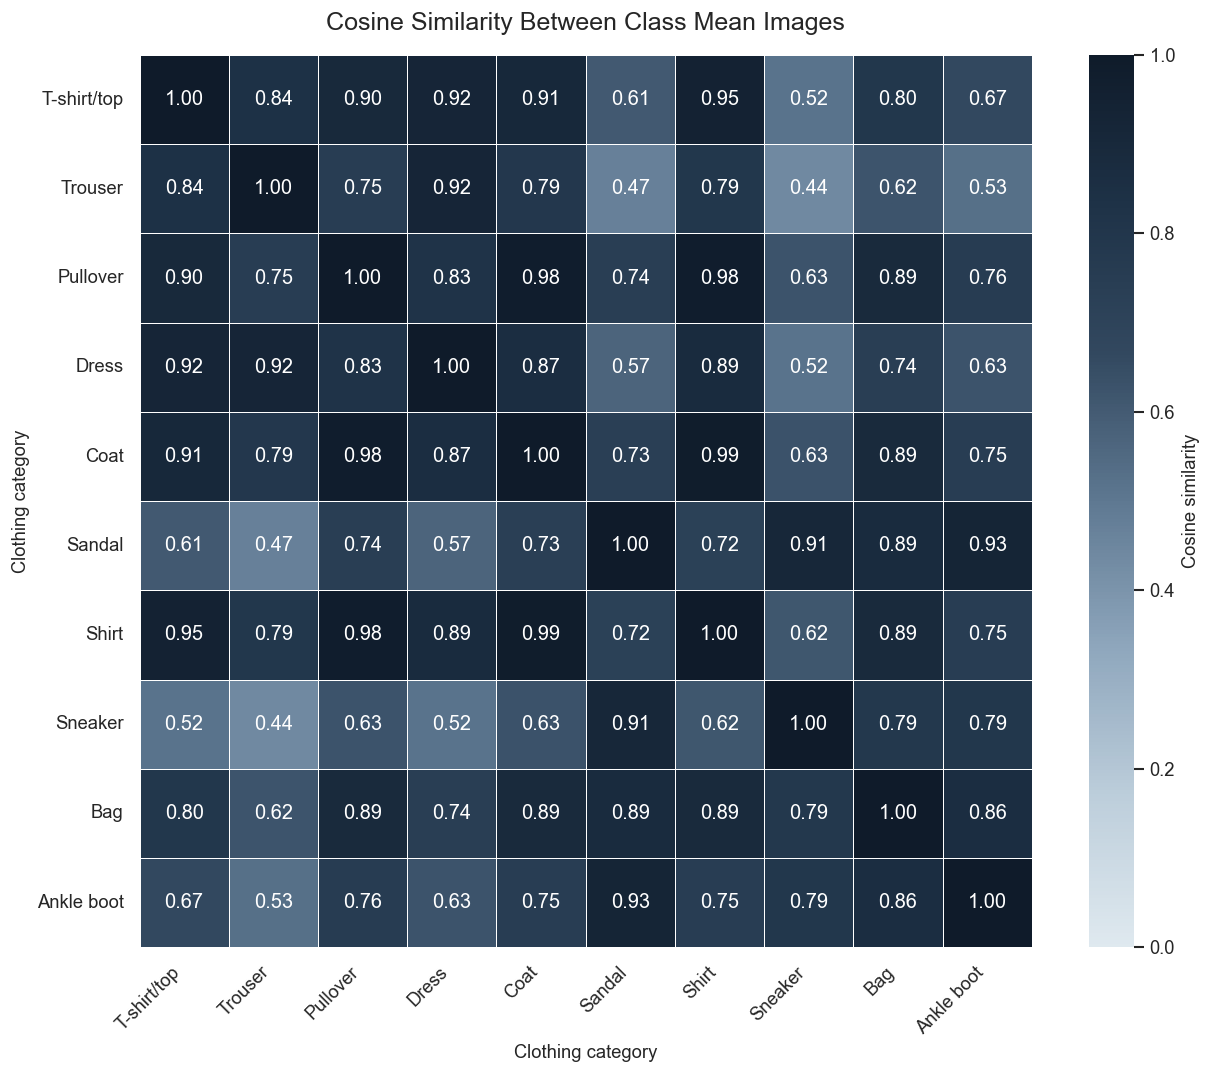

In [17]:
from matplotlib.colors import LinearSegmentedColormap

project_cmap = LinearSegmentedColormap.from_list(
    "project_palette",
    PROJECT_PALETTE,
)

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    similarity_df,
    annot=True,
    fmt=".2f",
    cmap=project_cmap,
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Cosine similarity"},
    ax=ax,
)

ax.set_title(
    "Cosine Similarity Between Class Mean Images",
    fontsize=15,
    pad=15,
)

ax.set_xlabel("Clothing category")
ax.set_ylabel("Clothing category")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "class_cosine_similarity.png",
    bbox_inches="tight",
)

plt.show()

In [18]:
similarity_pairs = []

for i in range(len(class_names)):
    for j in range(i + 1, len(class_names)):
        similarity_pairs.append(
            {
                "Class A": class_names[i],
                "Class B": class_names[j],
                "Cosine similarity": similarity_matrix[i, j],
            }
        )

similarity_pairs = pd.DataFrame(similarity_pairs)

similarity_pairs = similarity_pairs.sort_values(
    "Cosine similarity",
    ascending=False,
).reset_index(drop=True)

print("Top 5 most similar class pairs:")
display(similarity_pairs.head(5).round(4))

print("Top 5 least similar class pairs:")
display(similarity_pairs.tail(5).sort_values("Cosine similarity").round(4))

Top 5 most similar class pairs:


,Class A,Class B,Cosine similarity
0,Coat,Shirt,0.9874
1,Pullover,Coat,0.9841
2,Pullover,Shirt,0.9832
3,T-shirt/top,Shirt,0.9489
4,Sandal,Ankle boot,0.9269


Top 5 least similar class pairs:


,Class A,Class B,Cosine similarity
44,Trouser,Sneaker,0.4404
43,Trouser,Sandal,0.4706
42,Dress,Sneaker,0.5171
41,T-shirt/top,Sneaker,0.5180
40,Trouser,Ankle boot,0.5294


### 6.4. Key Findings

The cosine similarity analysis of class-level mean images
reveals substantial variation in inter-class visual similarity.

- The highest similarities were observed among upper-body
  clothing categories, especially Coat–Shirt,
  Pullover–Coat and Pullover–Shirt.
- T-shirt/top and Shirt also show high similarity,
  supporting the expectation that these categories may
  be difficult to separate.
- Among footwear-related categories, Sandal and Ankle boot
  exhibit relatively high similarity at the level of mean images.
- The lowest similarities were observed between Trouser
  and footwear categories such as Sneaker and Sandal,
  indicating clearly different global visual structures.

These findings suggest that some classification errors may
be linked to genuine visual similarity between categories.

However, cosine similarity between mean images does not
fully capture within-class variability and should therefore
be interpreted as a descriptive indicator rather than a
direct measure of classification difficulty.

## 7. PCA Explained Variance

This section examines how many principal components are
required to retain a large proportion of the variance
present in the final training subset.

The analysis is performed exclusively on the shared
50,000-sample training split to avoid information leakage
from the validation or test data.

The resulting cumulative explained variance curve provides
an empirical basis for selecting candidate PCA dimensions
for later machine learning experiments.

In [19]:
from sklearn.decomposition import PCA

In [20]:
from src.preprocessing.dataset import load_dataset
from src.preprocessing.ml import build_ml_datasets
from src.preprocessing.split import load_split

# Load shared dataset and split
train_dataset, test_dataset = load_dataset()
train_indices, val_indices = load_split()

# Build baseline ML datasets
datasets, preprocessor = build_ml_datasets(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    train_indices=train_indices,
    val_indices=val_indices,
    standardize=False,
    pca_components=None,
    use_hog=False,
    seed=RANDOM_SEED,
)

X_train_pca, y_train_pca = datasets["train"]

print("Training feature matrix shape:", X_train_pca.shape)
print("Training label vector shape:", y_train_pca.shape)
print("Feature range:", X_train_pca.min(), "to", X_train_pca.max())

Training feature matrix shape: (50000, 784)
Training label vector shape: (50000,)
Feature range: 0.0 to 1.0


In [21]:
from time import perf_counter

In [22]:
pca_start = perf_counter()

pca = PCA(random_state=RANDOM_SEED)
pca.fit(X_train_pca)

pca_time = perf_counter() - pca_start

print(f"PCA fitting completed in {pca_time:.2f} seconds.")

PCA fitting completed in 0.28 seconds.


In [23]:
cumulative_explained_variance = np.cumsum(pca.explained_variance_ratio_)

pca_summary = pd.DataFrame(
    {
        "Number of components": np.arange(1, len(cumulative_explained_variance) + 1),
        "Cumulative explained variance": cumulative_explained_variance,
    }
)

display(pca_summary.head())
display(pca_summary.tail())

,Number of components,Cumulative explained variance
0,1,0.290243
1,2,0.467865
2,3,0.528122
3,4,0.577397
4,5,0.615945


,Number of components,Cumulative explained variance
779,780,1.0
780,781,1.0
781,782,1.0
782,783,1.0
783,784,1.0


In [24]:
thresholds = [0.90, 0.95, 0.99]

threshold_results = []

for threshold in thresholds:
    n_components = np.argmax(cumulative_explained_variance >= threshold) + 1

    threshold_results.append(
        {
            "Explained variance threshold": f"{int(threshold * 100)}%",
            "Required components": n_components,
        }
    )

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results)

,Explained variance threshold,Required components
0,90%,84
1,95%,187
2,99%,459


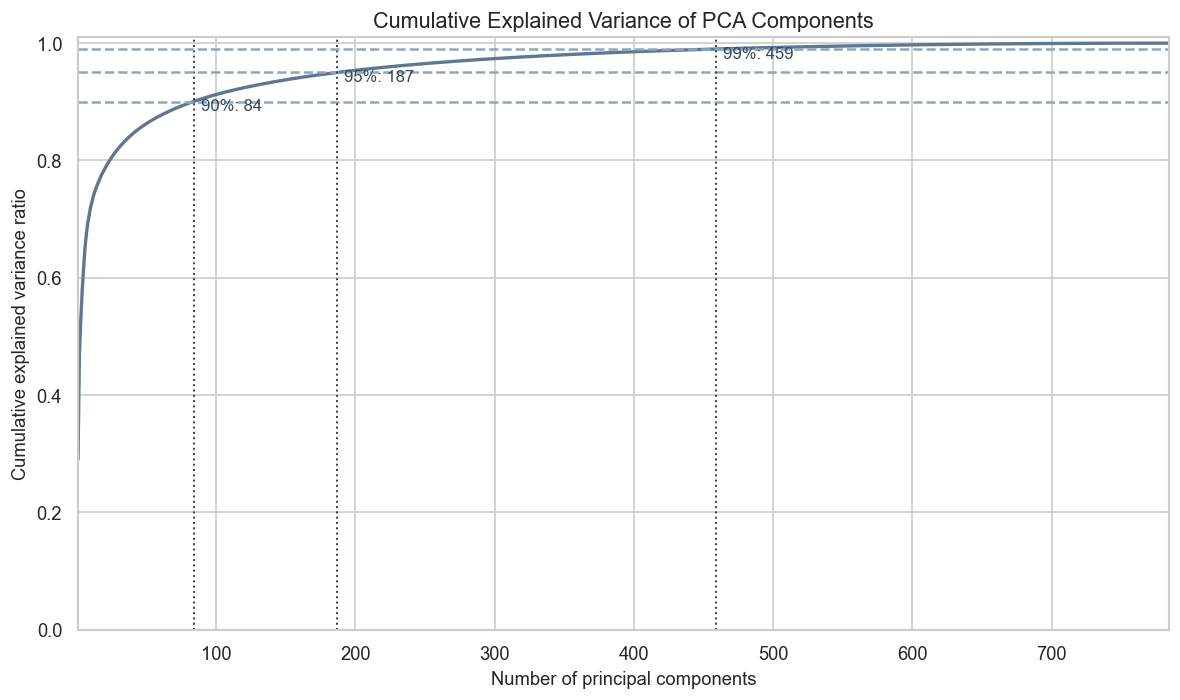

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    np.arange(1, len(cumulative_explained_variance) + 1),
    cumulative_explained_variance,
    color=PRIMARY_COLOR,
    linewidth=2,
)

for threshold, label in zip(
    [0.90, 0.95, 0.99],
    ["90%", "95%", "99%"],
):
    ax.axhline(
        y=threshold,
        color=ACCENT_COLOR,
        linestyle="--",
        linewidth=1.5,
    )

    n_components = np.argmax(cumulative_explained_variance >= threshold) + 1

    ax.axvline(
        x=n_components,
        color=SECONDARY_COLOR,
        linestyle=":",
        linewidth=1.2,
    )

    ax.text(
        n_components + 5,
        threshold - 0.015,
        f"{label}: {n_components}",
        fontsize=10,
        color=SECONDARY_COLOR,
    )

ax.set_title("Cumulative Explained Variance of PCA Components")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance ratio")
ax.set_xlim(1, len(cumulative_explained_variance))
ax.set_ylim(0, 1.01)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "pca_explained_variance.png",
    bbox_inches="tight",
)

plt.show()

### 7.4. Key Findings

The PCA analysis was performed exclusively on the
final 50,000-sample training subset.

The results indicate that a substantial proportion of
the original pixel variance can be retained using
significantly fewer features.

- 84 components are sufficient to retain 90% of the
  total variance, reducing dimensionality by 89.3%.
- 187 components retain 95% of the variance, reducing
  dimensionality by 76.1%.
- 459 components retain 99% of the variance, reducing
  dimensionality by 41.5%.

The cumulative explained variance curve demonstrates
diminishing returns as additional components are retained.

These results provide an empirical basis for selecting
candidate PCA configurations for subsequent machine
learning experiments.

However, explained variance does not directly measure
predictive relevance. The final configuration must
therefore be selected based on validation performance.

## 8. Key Findings and Modeling Implications

The exploratory data analysis provides the following
insights into the original Fashion-MNIST training dataset.

### Data Quality

All 60,000 images are unique, and no missing values,
invalid labels or structural inconsistencies were identified.

No data cleaning or exact duplicate removal is required
based on the performed checks.

### Class Distribution

The dataset is perfectly balanced, with 6,000 images
per class. Class balancing techniques are therefore
not required for the baseline experiments.

Stratified sampling is recommended for the shared
training and validation split.

### Pixel Intensity Characteristics

Approximately 50.21% of all pixels have zero intensity.
Substantial differences in mean pixel intensity and
background coverage were observed across clothing classes.

### Visual Characteristics

Global pixel statistics are similar for some clothing
categories. Spatial patterns and local image features
may therefore contribute to more accurate classification.

### Inter-Class Visual Similarity

The highest cosine similarities between class-level
mean images were observed among upper-body clothing
categories, particularly Coat, Shirt and Pullover.

These results provide a descriptive reference for
investigating potential misclassification patterns
in subsequent model evaluations.

### Dimensionality Reduction

The PCA analysis demonstrates that 90% and 95% of the
training data variance can be retained using only
84 and 187 components, respectively.

These findings support investigating dimensionality
reduction as a potential approach to improving
computational efficiency.

### Implications for Model Development

- Preserve the shared dataset and class distribution.
- Scale pixel intensities consistently across models.
- Estimate data-dependent normalization parameters
  exclusively from the final training subset.
- Investigate both flattened pixel representations
  and spatial image representations.
- Evaluate models using accuracy, macro F1-score
  and class-level confusion matrices.
- Investigate potential classification difficulties
  between visually similar clothing categories.
- Compare class-level cosine similarities with observed
  misclassification patterns.
- Investigate empirically selected PCA dimensions
  using validation-based model evaluation.

The official test dataset remains reserved for final
model evaluation.